# 🦠 Análisis Exploratorio de Datos — COVID-19 en Estados Unidos

**Fuente:** [The COVID Tracking Project](https://covidtracking.com/data/download) — datos públicos de casos, pruebas, hospitalizaciones y fallecimientos por estado, del 13-ene-2020 al 07-mar-2021.

**Qué buscamos (las 3 preguntas guía):**

1. ¿Qué estados vivieron la pandemia peor **ajustando por población** (no en totales absolutos)?
2. ¿Existe relación entre **lo que se testea** y lo que ocurre en **los hospitales**?
3. ¿Cuándo fueron los **peores momentos** y ¿coincidieron en el tiempo en todos los estados?

---

## 📥 Paso 1 — Carga de los datos

La API es pública, pero el fichero pesa ~29 MB. Para no pedirlo en cada ejecución, **cacheamos un CSV local** en `data/raw/`: si ya existe, lo leemos de disco; si no, lo descargamos una vez.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import requests

pd.set_option("display.max_columns", 100)

URL = "https://api.covidtracking.com/v1/states/daily.json"
RAW_DIR = Path("../data/raw")
RAW_DIR.mkdir(parents=True, exist_ok=True)
CSV_PATH = RAW_DIR / "covid_tracking.csv"

In [2]:
def cargar_datos(url: str = URL, csv_path: Path = CSV_PATH) -> pd.DataFrame:
    """Descarga los datos de la API y los cachea en local.
    
    Si el CSV ya existe, se lee de disco (evita volver a descargar ~29 MB).
    """
    if csv_path.exists():
        print(f"Leyendo cache local: {csv_path}")
        return pd.read_csv(csv_path)

    print(f"Descargando {url} ...")
    respuesta = requests.get(url, timeout=60)
    respuesta.raise_for_status()  # falla claro si la API no responde 200
    df = pd.DataFrame(respuesta.json())
    df.to_csv(csv_path, index=False)
    print(f"Guardado en {csv_path} ({csv_path.stat().st_size / 1e6:.1f} MB)")
    return df


df = cargar_datos()
print(f"Dimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas")

Leyendo cache local: ..\data\raw\covid_tracking.csv


Dimensiones: 20,780 filas x 56 columnas


### 🔍 Primer vistazo

Antes de tocar nada: `head()` para ver de qué va cada fila, `info()` para ver tipos y nulos reales, y `describe()` para hacernos una idea de los rangos numéricos.

Cada fila es **un estado (o territorio) en un día concreto**.

In [3]:
df.head()

,date,state,positive,probableCases,negative,pending,totalTestResultsSource,totalTestResults,hospitalizedCurrently,hospitalizedCumulative,inIcuCurrently,inIcuCumulative,onVentilatorCurrently,onVentilatorCumulative,recovered,lastUpdateEt,dateModified,checkTimeEt,death,hospitalized,hospitalizedDischarged,dateChecked,totalTestsViral,positiveTestsViral,negativeTestsViral,positiveCasesViral,deathConfirmed,deathProbable,totalTestEncountersViral,totalTestsPeopleViral,totalTestsAntibody,positiveTestsAntibody,negativeTestsAntibody,totalTestsPeopleAntibody,positiveTestsPeopleAntibody,negativeTestsPeopleAntibody,totalTestsPeopleAntigen,positiveTestsPeopleAntigen,totalTestsAntigen,positiveTestsAntigen,fips,positiveIncrease,negativeIncrease,total,totalTestResultsIncrease,posNeg,dataQualityGrade,deathIncrease,hospitalizedIncrease,hash,commercialScore,negativeRegularScore,negativeScore,positiveScore,score,grade
0,20210307,AK,56886.0,NaN,NaN,NaN,totalTestsViral,1731628.0,33.0,1293.0,NaN,NaN,2.0,NaN,NaN,3/5/2021 03:59,2021-03-05T03:59:00Z,03/04 22:59,305.0,1293.0,NaN,2021-03-05T03:59:00Z,1731628.0,68693.0,1660758.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,0,0,56886,0,56886,NaN,0,0,dc4bccd4bb885349d7e94d6fed058e285d4be164,0,0,0,0,0,NaN
1,20210307,AL,499819.0,107742.0,1931711.0,NaN,totalTestsPeopleViral,2323788.0,494.0,45976.0,NaN,2676.0,NaN,1515.0,295690.0,3/7/2021 11:00,2021-03-07T11:00:00Z,03/07 06:00,10148.0,45976.0,NaN,2021-03-07T11:00:00Z,NaN,NaN,NaN,392077.0,7963.0,2185.0,NaN,2323788.0,NaN,NaN,NaN,119757.0,NaN,NaN,NaN,NaN,NaN,NaN,1,408,2087,2431530,2347,2431530,NaN,-1,0,997207b430824ea40b8eb8506c19a93e07bc972e,0,0,0,0,0,NaN
2,20210307,AR,324818.0,69092.0,2480716.0,NaN,totalTestsViral,2736442.0,335.0,14926.0,141.0,NaN,65.0,1533.0,315517.0,3/7/2021 00:00,2021-03-07T00:00:00Z,03/06 19:00,5319.0,14926.0,NaN,2021-03-07T00:00:00Z,2736442.0,NaN,2480716.0,255726.0,4308.0,1011.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,481311.0,81803.0,NaN,NaN,5,165,3267,2805534,3380,2805534,NaN,22,11,50921aeefba3e30d31623aa495b47fb2ecc72fae,0,0,0,0,0,NaN
3,20210307,AS,0.0,NaN,2140.0,NaN,totalTestsViral,2140.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12/1/2020 00:00,2020-12-01T00:00:00Z,11/30 19:00,0.0,NaN,NaN,2020-12-01T00:00:00Z,2140.0,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,60,0,0,2140,0,2140,NaN,0,0,f77912d0b80d579fbb6202fa1a90554fc4dc1443,0,0,0,0,0,NaN
4,20210307,AZ,826454.0,56519.0,3073010.0,NaN,totalTestsViral,7908105.0,963.0,57907.0,273.0,NaN,143.0,NaN,NaN,3/7/2021 00:00,2021-03-07T00:00:00Z,03/06 19:00,16328.0,57907.0,118932.0,2021-03-07T00:00:00Z,7908105.0,NaN,NaN,769935.0,14403.0,1925.0,NaN,3842945.0,580569.0,NaN,NaN,444089.0,NaN,NaN,NaN,NaN,NaN,NaN,4,1335,13678,3899464,45110,3899464,NaN,5,44,0437a7a96f4471666f775e63e86923eb5cbd8cdf,0,0,0,0,0,NaN


In [4]:
df.info(memory_usage="deep")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20780 entries, 0 to 20779
Data columns (total 56 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   date                         20780 non-null  int64  
 1   state                        20780 non-null  object 
 2   positive                     20592 non-null  float64
 3   probableCases                9271 non-null   float64
 4   negative                     13290 non-null  float64
 5   pending                      2138 non-null   float64
 6   totalTestResultsSource       20780 non-null  object 
 7   totalTestResults             20614 non-null  float64
 8   hospitalizedCurrently        17339 non-null  float64
 9   hospitalizedCumulative       12382 non-null  float64
 10  inIcuCurrently               11636 non-null  float64
 11  inIcuCumulative              3789 non-null   float64
 12  onVentilatorCurrently        9126 non-null   float64
 13  onVentilatorCumu

In [5]:
df.describe().T  # .T para leer cada variable en una fila

,count,mean,std,min,25%,50%,75%,max
date,20780.0,2.020244e+07,3.608732e+03,20200113.0,20200602.00,20200903.0,20201205.00,20210307.0
positive,20592.0,1.651560e+05,3.267852e+05,0.0,5753.75,46064.5,177958.00,3501394.0
probableCases,9271.0,2.172912e+04,4.547146e+04,0.0,773.50,4491.0,19553.00,365961.0
negative,13290.0,8.482246e+05,1.344501e+06,0.0,53941.25,305972.0,1056611.25,10186941.0
pending,2138.0,1.659863e+03,4.671029e+03,0.0,43.00,212.5,1295.75,64400.0
totalTestResults,20614.0,2.186936e+06,4.436508e+06,0.0,104049.75,655267.0,2264766.50,49646014.0
hospitalizedCurrently,17339.0,1.190577e+03,2.060041e+03,0.0,166.50,531.0,1279.00,22851.0
hospitalizedCumulative,12382.0,9.262762e+03,1.262054e+04,1.0,985.25,4472.0,12248.50,82237.0
inIcuCurrently,11636.0,3.596212e+02,5.948311e+02,0.0,60.00,172.0,380.00,5225.0
inIcuCumulative,3789.0,1.934192e+03,1.953330e+03,6.0,501.00,1295.0,2451.00,9263.0


---

## 🧹 Paso 2 — Diagnóstico de calidad

Aquí **solo diagnosticamos**, aún no corregimos. Necesitamos saber:

- ¿Cuántos valores faltantes hay por columna?
- ¿Hay filas duplicadas?
- ¿Los tipos de datos son los correctos?

In [6]:
# Valores faltantes por columna, ordenados de mayor a menor
nulos = (
    df.isna().sum()
    .to_frame("n_nulos")
    .assign(pct=lambda t: (t["n_nulos"] / len(df) * 100).round(1))
    .sort_values("pct", ascending=False)
)
nulos[nulos["n_nulos"] > 0]

,n_nulos,pct
dataQualityGrade,20780,100.0
grade,20780,100.0
positiveTestsPeopleAntigen,20147,97.0
negativeTestsPeopleAntibody,19808,95.3
totalTestsPeopleAntigen,19781,95.2
positiveTestsPeopleAntibody,19686,94.7
onVentilatorCumulative,19490,93.8
negativeTestsAntibody,19322,93.0
pending,18642,89.7
totalTestsPeopleAntibody,18580,89.4


In [7]:
# Filas duplicadas. Clave lógica: un estado solo puede aparecer una vez por día
duplicadas = df.duplicated(subset=["date", "state"], keep=False)
print(f"Filas duplicadas por (date, state): {duplicadas.sum()}")
df.loc[duplicadas].head()

Filas duplicadas por (date, state): 0


,date,state,positive,probableCases,negative,pending,totalTestResultsSource,totalTestResults,hospitalizedCurrently,hospitalizedCumulative,inIcuCurrently,inIcuCumulative,onVentilatorCurrently,onVentilatorCumulative,recovered,lastUpdateEt,dateModified,checkTimeEt,death,hospitalized,hospitalizedDischarged,dateChecked,totalTestsViral,positiveTestsViral,negativeTestsViral,positiveCasesViral,deathConfirmed,deathProbable,totalTestEncountersViral,totalTestsPeopleViral,totalTestsAntibody,positiveTestsAntibody,negativeTestsAntibody,totalTestsPeopleAntibody,positiveTestsPeopleAntibody,negativeTestsPeopleAntibody,totalTestsPeopleAntigen,positiveTestsPeopleAntigen,totalTestsAntigen,positiveTestsAntigen,fips,positiveIncrease,negativeIncrease,total,totalTestResultsIncrease,posNeg,dataQualityGrade,deathIncrease,hospitalizedIncrease,hash,commercialScore,negativeRegularScore,negativeScore,positiveScore,score,grade


In [8]:
# Comprobación de tipos: 'date' viene como entero (20200313), hay que convertirla
print("Tipo de 'date':", df["date"].dtype)
print("Ejemplo de valor:", df["date"].iloc[0])

df["date"] = pd.to_datetime(df["date"].astype(str), format="%Y%m%d")
print("Tipo tras convertir:", df["date"].dtype)
print("Rango temporal:", df["date"].min().date(), "->", df["date"].max().date())

Tipo de 'date': int64
Ejemplo de valor: 20210307
Tipo tras convertir: datetime64[ns]
Rango temporal: 2020-01-13 -> 2021-03-07


In [9]:
# Cobertura por estado: ¿todos los estados tienen los mismos días?
por_estado = (
    df.groupby("state")
    .agg(dias=("date", "count"), desde=("date", "min"), hasta=("date", "max"))
    .sort_values("dias")
)
por_estado

,dias,desde,hasta
state,,,
AS,357,2020-03-16,2021-03-07
GU,357,2020-03-16,2021-03-07
MP,357,2020-03-16,2021-03-07
PR,357,2020-03-16,2021-03-07
VI,357,2020-03-16,2021-03-07
MO,366,2020-03-07,2021-03-07
LA,366,2020-03-07,2021-03-07
ID,366,2020-03-07,2021-03-07
MT,366,2020-03-07,2021-03-07


### 📌 Primeras conclusiones del diagnóstico

- **Filas / columnas:** 20.780 filas × 56 columnas. Cada fila = un estado/territorio en un día.
  Del 13-ene-2020 al 07-mar-2021.
- **Columnas casi vacías (>80% nulos):** 15 columnas. Destacan `dataQualityGrade` y `grade`
  con **100% de nulos** (columnas muertas: se eliminan sin dudarlo), y un bloque entero de
  tests de antígeno/anticuerpos (`*Antigen`, `*Antibody`, 83–97% nulos) que muchos estados
  no empezaron a reportar hasta tarde. También `onVentilatorCumulative` (93,8%),
  `pending` (89,7%) y `hospitalizedDischarged` (85,2%).
- **Duplicados:** 0 por la clave lógica `(date, state)`. No hay filas repetidas.
- **Tipos corregidos:** `date` era entero (`20200313`) → `datetime64` con
  `pd.to_datetime(..., format="%Y%m%d")`.
- **Cobertura:** 56 estados/territorios, pero **desigual**. Todos terminan el 07-mar-2021,
  pero empiezan en fechas distintas: Washington desde el 13-ene-2020 (420 días), Massachusetts
  el 22-ene, Florida el 29-ene... mientras que los territorios (Puerto Rico, Guam, Islas Vírgenes)
  solo tienen datos desde el 16-mar-2020 (357 días). Tiene sentido: la pandemia llegó a cada
  estado por fechas distintas y cada administración empezó a medir cuando pudo.
  → Al comparar estados, usar tasas y periodos comunes, no totales brutos.
- **Nulos moderados a vigilar:** `death` (4,1%), `positive` (0,9%), `totalTestResults` (0,8%)
  — son columnas clave, así que sus pocos nulos hay que tratarlos en la limpieza.

---

## 🧹 Paso 3 — Eliminar columnas: fuera lo que no sirve

Del diagnóstico anterior salen dos categorías de columnas **inútiles**, y las dos se
eliminan por la misma razón: *no responden a ninguna de nuestras preguntas*.

| Tipo | Criterio | Ejemplos | Por qué se va |
|---|---|---|---|
| Casi vacías | **> 80 % de nulos** | tests de antígeno/anticuerpo, `pending` | Sus valores no existen: no hay nada que analizar |
| Columnas muertas | **0 valores distintos** (siempre lo mismo) | `grade`, `score`, `dataQualityGrade` | No varían → no explican nada |

No borramos información real: solo columnas que estaban vacías o repitiendo siempre
lo mismo. *(En el nivel medio se retoma este criterio con una tabla de justificación
por columna.)*

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Columnas inutiles: >80% de nulos O practicamente constantes (1 valor distinto)
pct_nulos = df.isna().mean()
constantes = df.nunique(dropna=False) <= 1
inutiles = sorted(set(df.columns[(pct_nulos > 0.8) | constantes]))

df_limpio = df.drop(columns=inutiles)
print(f"{df.shape[1]} columnas -> {df_limpio.shape[1]} tras eliminar {len(inutiles)} inutiles")
print("Eliminadas:", ", ".join(inutiles))

# Nos aseguramos de no habernos comido ninguna columna que necesitamos
claves = ["date", "state", "positive", "death", "totalTestResults",
          "positiveIncrease", "deathIncrease", "hospitalizedCurrently"]
assert set(claves) <= set(df_limpio.columns), "Ups: se elimino una columna necesaria"
print("Columnas clave conservadas: OK")

56 columnas -> 36 tras eliminar 20 inutiles
Eliminadas: commercialScore, dataQualityGrade, grade, hospitalizedDischarged, inIcuCumulative, negativeRegularScore, negativeScore, negativeTestsAntibody, negativeTestsPeopleAntibody, onVentilatorCumulative, pending, positiveScore, positiveTestsAntibody, positiveTestsAntigen, positiveTestsPeopleAntibody, positiveTestsPeopleAntigen, score, totalTestsAntigen, totalTestsPeopleAntibody, totalTestsPeopleAntigen
Columnas clave conservadas: OK


---

## 📊 Paso 4 — Análisis univariado: una variable a la vez

Tres variables, tres formas de mirarlas:

1. **`deathIncrease`** (muertes diarias) → *histograma*: ¿cómo se reparten los días?
2. **`totalTestResultsIncrease`** (pruebas diarias) → *histograma*: ¿hay días "raros"?
3. **`positiveIncrease`** (casos diarios) → *boxplot*: ¿qué días se escapan de lo normal?

Y un **conteo** de la estructura temporal: cuántos registros aporta cada mes.

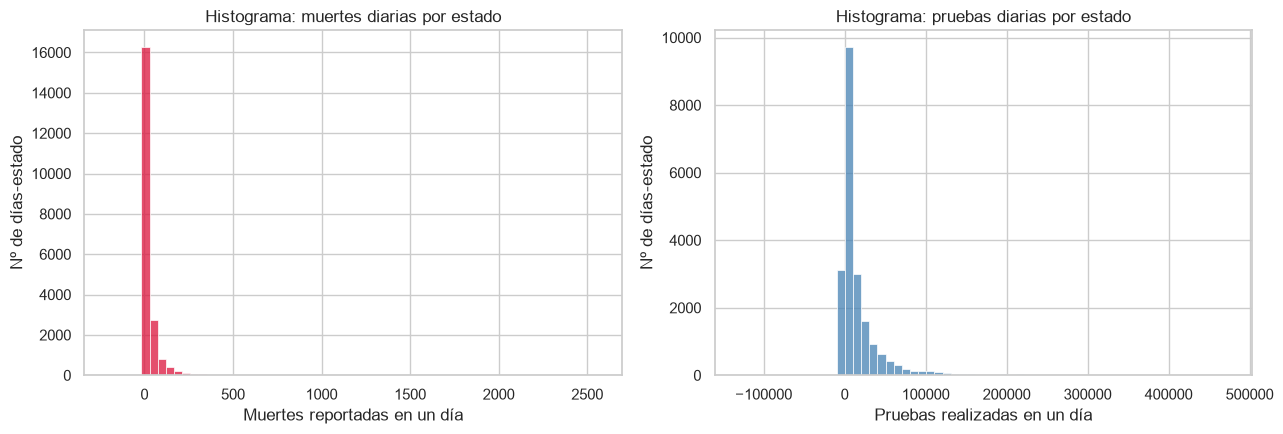

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(df_limpio["deathIncrease"], bins=60, ax=axes[0], color="crimson")
axes[0].set_title("Histograma: muertes diarias por estado")
axes[0].set_xlabel("Muertes reportadas en un día")
axes[0].set_ylabel("Nº de días-estado")

sns.histplot(df_limpio["totalTestResultsIncrease"], bins=60, ax=axes[1], color="steelblue")
axes[1].set_title("Histograma: pruebas diarias por estado")
axes[1].set_xlabel("Pruebas realizadas en un día")
axes[1].set_ylabel("Nº de días-estado")

plt.tight_layout()
plt.show()

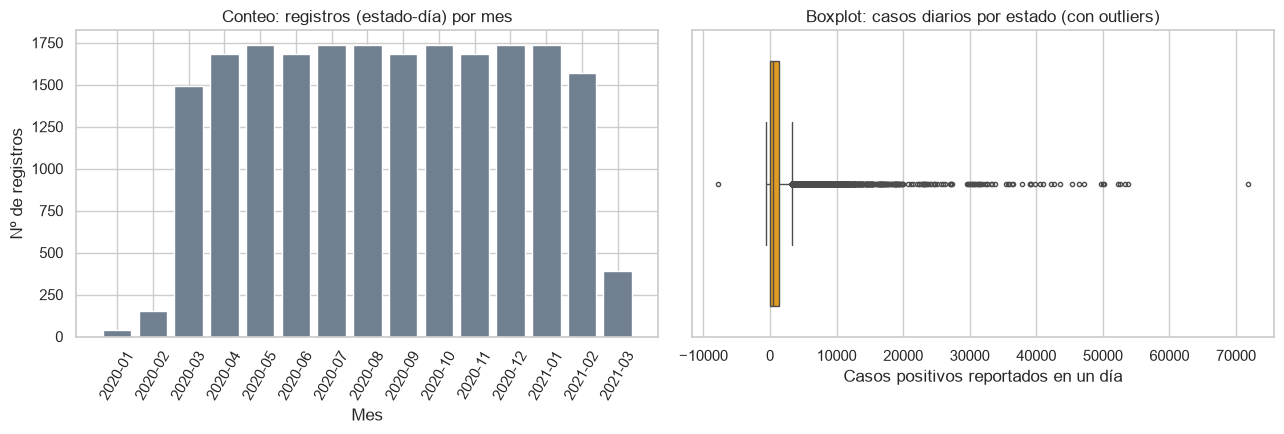

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Conteo: registros por mes (actividad de reporte de los estados)
por_mes = df_limpio["date"].dt.to_period("M").astype(str).value_counts().sort_index()
axes[0].bar(por_mes.index, por_mes.values, color="slategray")
axes[0].set_title("Conteo: registros (estado-día) por mes")
axes[0].set_xlabel("Mes")
axes[0].set_ylabel("Nº de registros")
axes[0].tick_params(axis="x", rotation=60)

# Boxplot: dispersion de casos diarios y dias que se escapan
sns.boxplot(x=df_limpio["positiveIncrease"], ax=axes[1], color="orange", fliersize=3)
axes[1].set_title("Boxplot: casos diarios por estado (con outliers)")
axes[1].set_xlabel("Casos positivos reportados en un día")

plt.tight_layout()
plt.show()

---

## 🔗 Paso 5 — Análisis bivariado: dos variables juntas

Tres relaciones que nos interesaban, una dispersión por cada pregunta:

1. **Pruebas ↔ casos**: ¿a más pruebas, más casos detectados?
2. **Casos ↔ muertes**: ¿los acumulados caminan juntos?
3. **Casos nuevos ↔ hospitalizados**: ¿los casos de hoy se reflejan en los hospitales?

El número `r` de cada panel es la correlación de Pearson (de -1 a +1): mide si las dos
variables suben y bajan juntas. **Correlación no implica causa.**

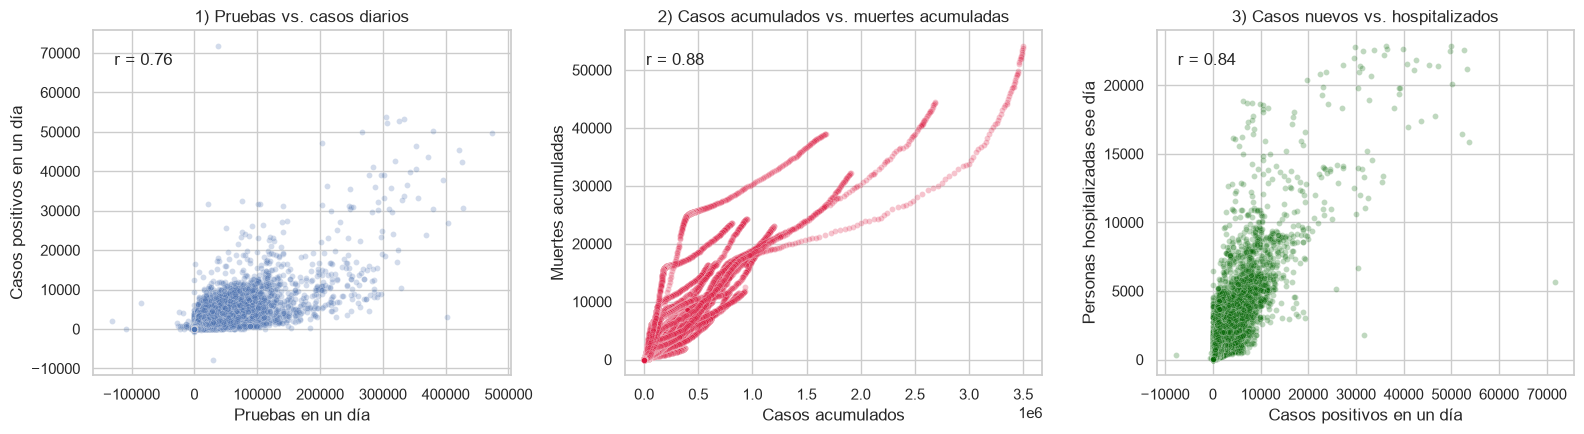

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
d = df_limpio

sns.scatterplot(x="totalTestResultsIncrease", y="positiveIncrease",
                data=d, alpha=0.25, s=18, ax=axes[0])
axes[0].set_title("1) Pruebas vs. casos diarios")
axes[0].set_xlabel("Pruebas en un día")
axes[0].set_ylabel("Casos positivos en un día")
axes[0].annotate(f"r = {d['totalTestResultsIncrease'].corr(d['positiveIncrease']):.2f}",
                 xy=(0.05, 0.9), xycoords="axes fraction", fontsize=12)

sns.scatterplot(x="positive", y="death", data=d, alpha=0.25, s=18,
                color="crimson", ax=axes[1])
axes[1].set_title("2) Casos acumulados vs. muertes acumuladas")
axes[1].set_xlabel("Casos acumulados")
axes[1].set_ylabel("Muertes acumuladas")
axes[1].annotate(f"r = {d['positive'].corr(d['death']):.2f}",
                 xy=(0.05, 0.9), xycoords="axes fraction", fontsize=12)

sns.scatterplot(x="positiveIncrease", y="hospitalizedCurrently",
                data=d, alpha=0.25, s=18, color="darkgreen", ax=axes[2])
axes[2].set_title("3) Casos nuevos vs. hospitalizados")
axes[2].set_xlabel("Casos positivos en un día")
axes[2].set_ylabel("Personas hospitalizadas ese día")
axes[2].annotate(f"r = {d['positiveIncrease'].corr(d['hospitalizedCurrently']):.2f}",
                 xy=(0.05, 0.9), xycoords="axes fraction", fontsize=12)

plt.tight_layout()
plt.show()

---

## ✅ Paso 6 — Respondiendo nuestras 3 preguntas

**1. ¿Qué estados vivieron la pandemia peor ajustando por población?**

Todavía no podemos responderlo *con justicia*: la población no está en este dataset
(la traemos en el **nivel avanzado**, cruzando con el Census Bureau). Por totales
crudos mandan **California, Texas y Nueva York**, pero eso habla de tamaño, no de
gravedad. → *Respuesta completa en el notebook 03 y en el informe ejecutivo.*

**2. ¿Existe relación entre lo que se testea y lo que ocurre en los hospitales?**

Sí, pero **no es causal**: pruebas y casos suben juntos (panel 1, r = 0,76) porque
más testeo descubre más casos de los que ya estaban ahí. Los hospitales,
en cambio, se llenan cuando el virus circula de verdad (panel 3). → *Detalle y
cifras en el notebook 02, secciones 7 y 9.*

**3. ¿Cuándo fueron los peores momentos y coincidieron en todos los estados?**

Tres picos: **abril de 2020** (Nueva York y el Noreste primero), **verano de 2020**
(el sur: Texas, Florida, Arizona) y **enero de 2021** (casi todos a la vez: ~247.000
casos y ~3.335 muertes al día del 11 al 13 de enero). No coincidieron del todo: cada
región vivió la suya. → *Gráficos de tendencia en el notebook 02, sección 8.*